In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_absolute_error , mean_squared_error , r2_score)
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor , GradientBoostingRegressor)
from sklearn.neighbors import KNeighborsRegressor
import xgboost as xgb
from sklearn.linear_model import LinearRegression
from pandas.plotting import scatter_matrix

In [2]:
dataframe = pd.read_csv('co2.csv')

In [3]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 7385 entries, 0 to 7384
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   engine         7385 non-null   float64
 1   cylinders      7385 non-null   int64  
 2   fuelcity       7385 non-null   float64
 3   fuelwy         7385 non-null   float64
 4   fuelcomb       7385 non-null   float64
 5   co2_emissions  7385 non-null   int64  
dtypes: float64(4), int64(2)
memory usage: 346.3 KB


In [4]:
dataframe.head(10)

,engine,cylinders,fuelcity,fuelwy,fuelcomb,co2_emissions
0,2.0,4,9.9,6.7,8.5,196
1,2.4,4,11.2,7.7,9.6,221
2,1.5,4,6.0,5.8,5.9,136
3,3.5,6,12.7,9.1,11.1,255
4,3.5,6,12.1,8.7,10.6,244
5,3.5,6,11.9,7.7,10.0,230
6,3.5,6,11.8,8.1,10.1,232
7,3.7,6,12.8,9.0,11.1,255
8,3.7,6,13.4,9.5,11.6,267
9,2.4,4,10.6,7.5,9.2,212


In [5]:
dataframe.tail(10)

,engine,cylinders,fuelcity,fuelwy,fuelcomb,co2_emissions
7375,2.0,4,11.3,7.5,9.6,223
7376,2.0,4,10.5,7.1,8.9,208
7377,2.0,4,11.0,7.4,9.4,219
7378,2.0,4,10.8,7.7,9.4,220
7379,2.0,4,10.2,7.5,9.0,210
7380,2.0,4,10.7,7.7,9.4,219
7381,2.0,4,11.2,8.3,9.9,232
7382,2.0,4,11.7,8.6,10.3,240
7383,2.0,4,11.2,8.3,9.9,232
7384,2.0,4,12.2,8.7,10.7,248


In [6]:
dataframe.describe()

,engine,cylinders,fuelcity,fuelwy,fuelcomb,co2_emissions
count,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000
mean,3.160068,5.615030,12.556534,9.041706,10.975071,250.584699
std,1.354170,1.828307,3.500274,2.224456,2.892506,58.512679
min,0.900000,3.000000,4.200000,4.000000,4.100000,96.000000
25%,2.000000,4.000000,10.100000,7.500000,8.900000,208.000000
50%,3.000000,6.000000,12.100000,8.700000,10.600000,246.000000
75%,3.700000,6.000000,14.600000,10.200000,12.600000,288.000000
max,8.400000,16.000000,30.600000,20.600000,26.100000,522.000000


In [7]:
dataframe.loc[0 , 'engine']

np.float64(2.0)

In [8]:
dataframe.isnull().sum()

engine           0
cylinders        0
fuelcity         0
fuelwy           0
fuelcomb         0
co2_emissions    0
dtype: int64

In [9]:
features_names = dataframe[['engine' , 'cylinders' , 'fuelcity' , 'fuelwy' , 'fuelcomb']]
target = dataframe['co2_emissions']

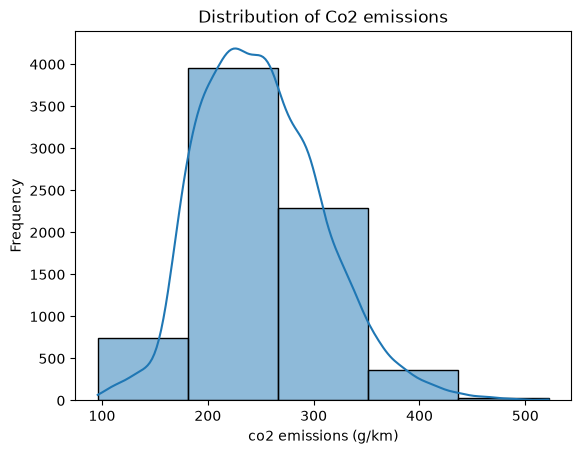

In [10]:
sns.histplot(data=dataframe , x='co2_emissions' , bins=5 , kde=True)

plt.title('Distribution of Co2 emissions')
plt.xlabel('co2 emissions (g/km)')
plt.ylabel('Frequency')
plt.show()

<Axes: >

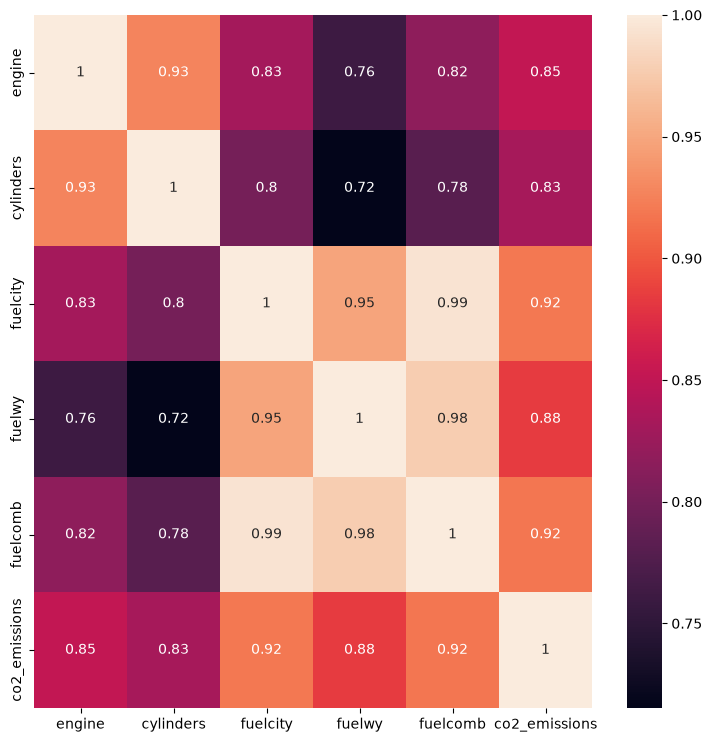

In [11]:
plt.subplots(figsize=(9,9))
sns.heatmap(dataframe.corr() , annot=True)

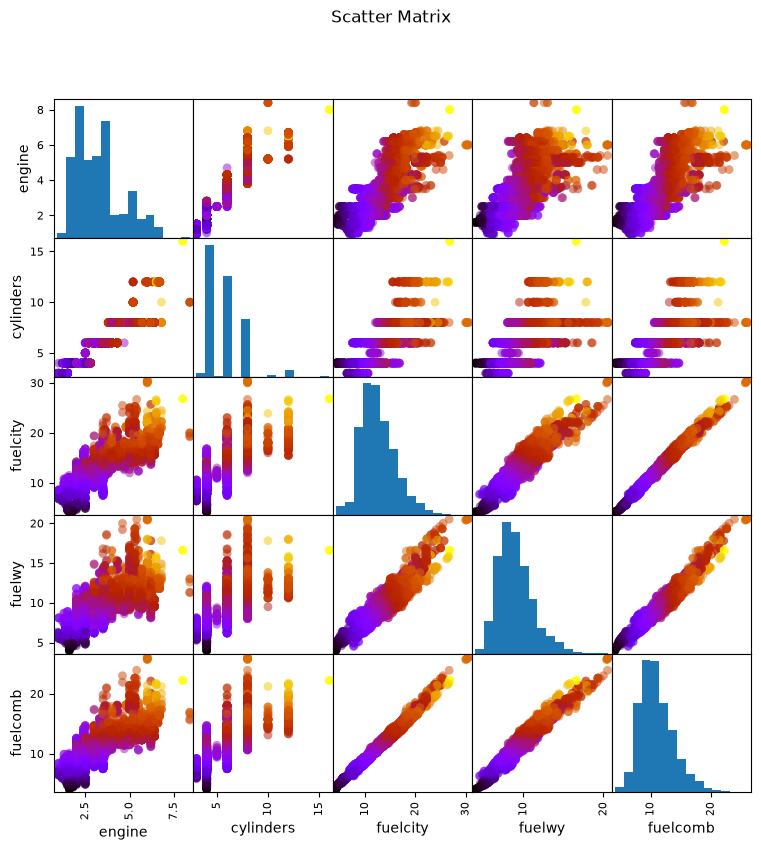

In [12]:
scatter_matrix = scatter_matrix(features_names , c = target , marker = 'o' , s = 40 , hist_kwds={'bins':15} , figsize=(9,9) , cmap='gnuplot')
plt.suptitle('Scatter Matrix')
plt.savefig('scatter_matrix.jpg')
plt.show()

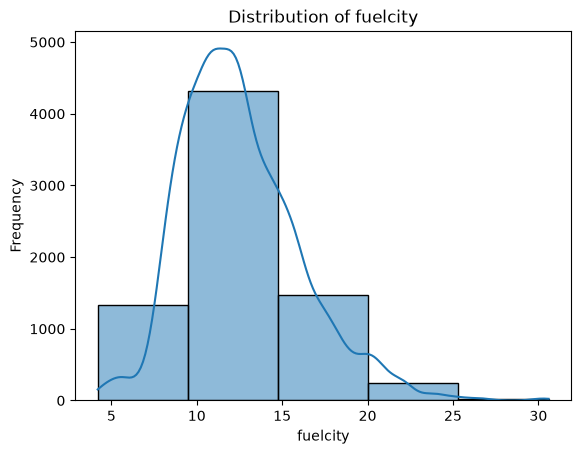

In [15]:
sns.histplot(data=dataframe , x='fuelcity' , bins=5 , kde=True)

plt.title('Distribution of fuelcity')
plt.xlabel('fuelcity')
plt.ylabel('Frequency')
plt.show()

In [16]:
X_train , X_valid , Y_train , Y_valid = train_test_split(features_names , target , test_size=0.2 , random_state=42)

In [18]:
models = [('LinearRegression' , LinearRegression()) , ('DecisionTreeRegressor' , DecisionTreeRegressor()) , 
          ('RandomForestRegressor' , RandomForestRegressor()) , ('KNN' , KNeighborsRegressor()) , ('XGBoost' , xgb.XGBRegressor()) , 
          ('GradientBoostingRegressor' , GradientBoostingRegressor())]

for name , model in models :
    model.fit(X_train , Y_train)
    y_pred = model.predict(X_valid)

    mae = mean_absolute_error(Y_valid , y_pred)
    rmse = np.sqrt(mean_squared_error(Y_valid , y_pred))
    r2 = r2_score(Y_valid , y_pred)

    car = [[2.0, 4, 9.9, 6.7, 8.5]]
    car2 = [[2.0 , 4 , 10.7 , 7.2 , 9.1]]
    prediction = model.predict(car)
    prediction2 = model.predict(car2)

    print(name)
    print('MAE:',mae)
    print('RMSE:',rmse)
    print('R2:', r2)
    print(prediction)
    print(prediction2)
    print('--------------')

c:\Users\HOSHMAND\Desktop\course\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\Users\HOSHMAND\Desktop\course\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


LinearRegression
MAE: 13.507511249284697
RMSE: 20.53932574881392
R2: 0.8773518607180024
[200.72185833]
[208.82290489]
--------------


c:\Users\HOSHMAND\Desktop\course\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(
c:\Users\HOSHMAND\Desktop\course\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


DecisionTreeRegressor
MAE: 3.3259321109132887
RMSE: 12.18292404789074
R2: 0.956848919819183
[198.33333333]
[211.]
--------------


c:\Users\HOSHMAND\Desktop\course\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\Users\HOSHMAND\Desktop\course\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


RandomForestRegressor
MAE: 3.2513657520748813
RMSE: 9.29356387810336
R2: 0.9748896263614355
[198.26191925]
[210.1025]
--------------
KNN
MAE: 3.948950575490859
RMSE: 10.128275442512619
R2: 0.970176431608272
[195.8]
[210.]
--------------


c:\Users\HOSHMAND\Desktop\course\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(
c:\Users\HOSHMAND\Desktop\course\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(


XGBoost
MAE: 3.341261386871338
RMSE: 8.131707811772085
R2: 0.9807756543159485
[198.009]
[210.71504]
--------------
GradientBoostingRegressor
MAE: 5.887839895456499
RMSE: 11.301011373151532
R2: 0.9628701476455063
[197.75247601]
[211.13615695]
--------------


c:\Users\HOSHMAND\Desktop\course\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(
c:\Users\HOSHMAND\Desktop\course\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(


In [13]:
car = [[2.0, 4, 9.9, 6.7, 8.5]]
car2 = [[2.0 , 4 , 10.7 , 7.2 , 9.1]]